# Ballot-level anomalies — Bulgarian presidential election, round 1 (25 Oct 2026)

The previous notebooks looked for **invented numbers** (Benford) and **stuffed ballot boxes** (turnout fingerprints). This one
targets manipulation that happens **during the count or at the voters' list**, which changes neither digits nor turnout:

| # | Question | Method |
|---|---|---|
| 1 | Do **paper-ballot** stations give different results than **machine** stations? (Committees can tamper with paper during the count, not with machines.) | **Regression discontinuity** at the legal 300-voter threshold |
| 2 | Are there stations with suspiciously many **invalid ballots**, and does a high invalid rate favour anyone? | Beta-binomial outlier test vs. the municipality, plus a within-municipality regression |
| 3 | How do **voters added on election day** (“под чертата”) vote, and where are there unusually many? | Fixed-effects regression, plus outlier test |
| 4 | Do the **protocols add up**? | Arithmetic consistency checks |
| 5 | Which stations raise **several red flags at once**? | Combined watch-list (incl. flags from the earlier notebooks) |

A note on wording: every test here finds **statistical anomalies**. An anomaly is a reason to look at the scanned protocol or
observer reports, not proof of fraud.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from load_data import load_votes, load_sections, DATA_DIR, DATE

votes = load_votes()
meta = load_sections()
NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP = ranked[:4]
OUTCOMES = TOP + [NONE]
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

# raw protocol rows (one main protocol per station: forms 24/26/28/30 = paper, 25/29 = machine)
proto = pd.read_csv(DATA_DIR / f"protocols_{DATE}.txt", sep=";", header=None, dtype=str, names=range(1, 29))
proto = proto.set_index(2)
num = lambda s: pd.to_numeric(s, errors="coerce")
main = proto[proto[1].isin(["24", "25", "26", "28", "29", "30"])]

df = meta.join(votes)
df["form"] = main[1].astype(int)
df["registered"] = df["voters_list"] + df["voters_added"]
df["voted"] = df["voted_signatures"]
df["turnout"] = df["voted"] / df["registered"]
df["valid"] = votes.sum(axis=1)
df["invalid"] = num(main[13]).reindex(df.index).fillna(0).astype(int)   # paper only; machines cannot produce invalid votes
df["paper"] = df["machines"] == 0
for c in votes.columns:
    df[f"share|{c}"] = df[c] / df["valid"]
dom = df[~df["abroad"] & (df["mobile"] == 0) & (df["ship"] == 0) & (df["valid"] > 0)].copy()
print(f"{len(dom):,} domestic regular stations: {dom['paper'].sum():,} paper-only, {(~dom['paper']).sum():,} with machines")

11,843 domestic regular stations: 2,470 paper-only, 9,373 with machines


In [2]:
# ---- chart style ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
    "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

# ---- small stats toolkit (numpy only) ----
def wls_cluster(y, X, w, groups):
    # Weighted least squares with cluster-robust (CR1) standard errors.
    y, X, w = np.asarray(y, float), np.asarray(X, float), np.asarray(w, float)
    sw = np.sqrt(w); Xw, yw = X * sw[:, None], y * sw
    XtX_inv = np.linalg.pinv(Xw.T @ Xw)
    beta = XtX_inv @ Xw.T @ yw
    u = yw - Xw @ beta
    g = pd.factorize(np.asarray(groups))[0]; G = g.max() + 1
    S = np.zeros((G, X.shape[1])); np.add.at(S, g, Xw * u[:, None])
    n, k = X.shape
    V = XtX_inv @ (S.T @ S) @ XtX_inv * (G / (G - 1)) * ((n - 1) / max(n - k, 1))
    return beta, np.sqrt(np.diag(V))

def demean(a, groups, w):
    # Subtract the weighted group mean = fixed effects for each group.
    a = pd.DataFrame(np.asarray(a, float)); g = pd.Series(np.asarray(groups)); w = pd.Series(np.asarray(w, float))
    m = a.mul(w, axis=0).groupby(g).transform("sum").div(w.groupby(g).transform("sum"), axis=0)
    return (a - m).to_numpy()

def betabinom_outliers(x, n, p_expected, q=0.01):
    # One-sided test for 'too many' events given an expected rate, allowing for over-dispersion (beta-binomial).
    # Returns (q-values, fitted intra-class correlation rho).
    # rho (extra between-station variation) is fitted by maximum likelihood.
    from scipy.optimize import minimize_scalar
    x, n, p = np.asarray(x, float), np.asarray(n, float), np.clip(np.asarray(p_expected, float), 1e-4, 0.999)
    xi, ni = x.astype(int), n.astype(int)
    nll = lambda r: -stats.betabinom.logpmf(xi, ni, p * (1 - r) / r, (1 - p) * (1 - r) / r).sum()
    rho = float(minimize_scalar(nll, bounds=(1e-5, 0.3), method="bounded").x)
    a, b = p * (1 - rho) / rho, (1 - p) * (1 - rho) / rho
    pv = np.where(x > 0, stats.betabinom.sf(x - 1, n.astype(int), a, b), 1.0)
    return stats.false_discovery_control(np.clip(pv, 0, 1)), rho

def loo_rate(events, trials, groups, fallback):
    # Rate in the rest of the municipality (leave-one-out), so a station isn't compared with itself.
    g = pd.Series(np.asarray(groups))
    e, t = pd.Series(np.asarray(events, float)), pd.Series(np.asarray(trials, float))
    r = (e.groupby(g).transform("sum") - e) / (t.groupby(g).transform("sum") - t)
    return r.where(np.isfinite(r), fallback).fillna(fallback).to_numpy()

## 1. Paper vs machine: a natural experiment at 300 voters
By law, stations with **300 or more** voters on the list vote by machine and smaller ones vote on paper. Our data follow the rule
exactly. Stations with 290 and 310 voters come from the same kinds of neighbourhoods; **only the voting method differs**.

So if paper counts were systematically manipulated in someone's favour, that candidate's share would **jump** at the 300 line.
This is a *regression discontinuity design* (RDD): fit a line on each side and measure the gap at 300.

In [3]:
lo_hi = dom.groupby(pd.cut(dom["voters_list"], [0, 200, 280, 300, 320, 400, 10**6], right=False), observed=True)["paper"].agg(["size", "mean"])
lo_hi.columns = ["stations", "share using paper"]
lo_hi.style.format({"share using paper": "{:.1%}"})

,stations,share using paper
voters_list,,
"[0, 200)",2025,95.9%
"[200, 280)",449,96.4%
"[280, 300)",96,95.8%
"[300, 320)",134,0.0%
"[320, 400)",536,0.2%
"[400, 1000000)",8603,0.0%


**Validity check: is there bunching at the threshold?** If officials split stations to keep them just under 300 (to avoid
machines), there would be too many stations at 280–299 and too few at 300–319. That would itself be a red flag, and it would
make the comparison unfair.

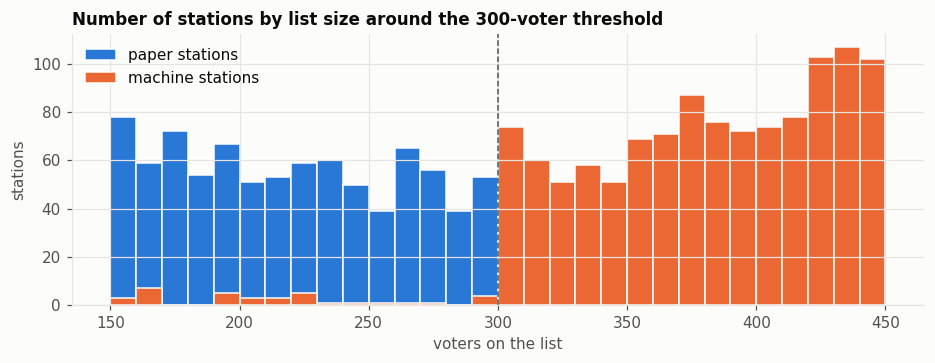

stations with 280–299 voters: 96;  300–319: 134  (binomial test for a difference: p = 0.01)


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
w = dom[(dom["voters_list"] >= 150) & (dom["voters_list"] < 450)]
bins = np.arange(150, 451, 10)
ax.hist(w.loc[w["paper"], "voters_list"], bins=bins, color=BLUE, edgecolor=SURFACE, label="paper stations")
ax.hist(w.loc[~w["paper"], "voters_list"], bins=bins, color=ORANGE, edgecolor=SURFACE, label="machine stations")
ax.axvline(300, color=INK2, lw=1, ls="--")
ax.set_xlabel("voters on the list"); ax.set_ylabel("stations"); ax.legend()
ax.set_title("Number of stations by list size around the 300-voter threshold")
plt.show()
below, above = ((w["voters_list"] >= 280) & (w["voters_list"] < 300)).sum(), ((w["voters_list"] >= 300) & (w["voters_list"] < 320)).sum()
print(f"stations with 280–299 voters: {below};  300–319: {above}  "
      f"(binomial test for a difference: p = {stats.binomtest(below, below + above).pvalue:.2f})")

In [5]:
def rd_estimate(data, y_col, bw, fe=False):
    s = data[(data["voters_list"] >= 300 - bw) & (data["voters_list"] < 300 + bw)]
    x = (s["voters_list"] - 300).to_numpy(float); M = (x >= 0).astype(float)
    y = s[y_col].to_numpy(float); wts = s["valid"].to_numpy(float)
    if fe:   # compare stations within the same municipality
        X = demean(np.column_stack([M, x, M * x]), s["municipality"], wts)
        y = demean(y, s["municipality"], wts)[:, 0]
        b, se = wls_cluster(y, X, wts, s["municipality"]); return b[0], se[0], len(s)
    X = np.column_stack([np.ones(len(s)), M, x, M * x])
    b, se = wls_cluster(y, X, wts, s["municipality"]); return b[1], se[1], len(s)

dom["invalid share"] = dom["invalid"] / (dom["invalid"] + dom["valid"])
rd_outcomes = {short(c): f"share|{c}" for c in OUTCOMES} | {"turnout": "turnout", "invalid ballots (positive control)": "invalid share"}
rows = {}
for name, col in rd_outcomes.items():
    for bw in [50, 100]:
        for fe in [False, True]:
            b, se, n = rd_estimate(dom, col, bw, fe)
            rows.setdefault(name, {})[f"±{bw} voters{' + municipality FE' if fe else ''}"] = f"{b*100:+.1f} ± {1.96*se*100:.1f}"
rd_tab = pd.DataFrame(rows).T
print("Jump at 300 voters (machine minus paper), percentage points, ± 95% CI")
rd_tab

Jump at 300 voters (machine minus paper), percentage points, ± 95% CI


,±50 voters,±50 voters + municipality FE,±100 voters,±100 voters + municipality FE
Илияна Йотова,-0.1 ± 4.8,-1.2 ± 4.5,+0.2 ± 3.7,-0.2 ± 2.8
Андрей Гюров,+2.3 ± 5.3,+0.5 ± 4.0,+1.4 ± 4.8,+0.3 ± 2.4
Костадин Костадинов,-0.2 ± 2.8,+0.5 ± 2.6,-0.4 ± 1.7,+0.0 ± 1.7
Радостин Василев,-2.1 ± 2.2,-1.4 ± 2.4,-1.2 ± 1.5,-0.9 ± 1.5
Не подкрепям никого,+0.4 ± 1.2,+0.2 ± 1.5,-0.3 ± 0.8,-0.7 ± 0.7
turnout,-0.7 ± 8.3,-1.3 ± 6.1,-0.8 ± 6.8,-1.0 ± 4.6
invalid ballots (positive control),-2.0 ± 0.6,-1.8 ± 0.9,-2.1 ± 0.4,-2.0 ± 0.5


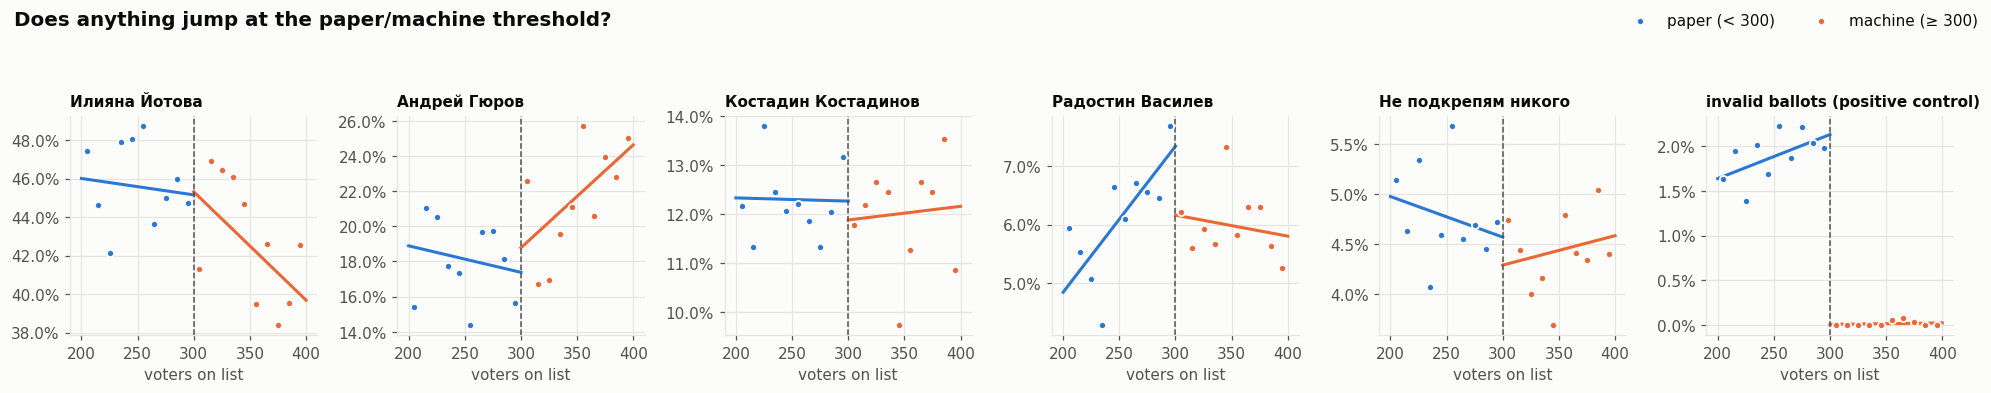

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
BW = 100
s = dom[(dom["voters_list"] >= 300 - BW) & (dom["voters_list"] < 300 + BW)].copy()
s["bin"] = (s["voters_list"] // 10) * 10 + 5
for ax, (name, col) in zip(axes, list(rd_outcomes.items())[:5] + [list(rd_outcomes.items())[-1]]):
    g = s.groupby("bin").apply(lambda t: np.average(t[col], weights=t["valid"]), include_groups=False)
    side = g.index >= 300
    ax.scatter(g.index[~side], g[~side], s=22, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="paper (< 300)")
    ax.scatter(g.index[side], g[side], s=22, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="machine (≥ 300)")
    for left, colr in [(True, BLUE), (False, ORANGE)]:
        t = s[(s["voters_list"] < 300) if left else (s["voters_list"] >= 300)]
        k = np.polyfit(t["voters_list"], t[col], 1, w=np.sqrt(t["valid"]))
        xx = np.array([200, 300]) if left else np.array([300, 400])
        ax.plot(xx, np.polyval(k, xx), color=colr, lw=2)
    ax.axvline(300, color=INK2, lw=1, ls="--")
    ax.set_title(name, fontsize=10); ax.set_xlabel("voters on list")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2)
suptitle(fig, "Does anything jump at the paper/machine threshold?")
fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

**Reading it:** the right-most panel is the **positive control**. Machines cannot produce invalid ballots, so the invalid share
*must* drop at 300, and the method detects that drop clearly (−2.0 ± 0.4 pts). For the candidates the lines show small visible gaps
(e.g. Гюров +1.4, Василев −1.2 pts), but they are **well inside the noise**: each bin holds only a few dozen stations, and the
confidence intervals in the table are ±1.5–5 pts. Comparing within the same municipality (FE) shrinks every gap to < 1 pt.

So in stations of 200–400 voters (mostly villages and small towns), paper counting doesn't measurably shift results compared
with machines. Systematic manipulation of paper counts in someone's favour would have to be smaller than ~2–3 points, or
confined to a few stations (see the outlier tests below).

## 2. Invalid ballots (paper stations only)
Declaring valid ballots invalid during the count is a classic way to take votes from a rival. Two checks:
1. **Outliers:** stations with far more invalid ballots than the rest of their municipality. We use a **beta-binomial** model
   because invalid rates vary more between stations than pure chance would predict; a plain binomial test would flag far too many.
   Multiple testing is controlled with Benjamini–Hochberg (q < 0.01).
2. **Who loses when invalid ballots are high?** Within the same municipality, regress each candidate's share on the station's invalid rate.

In [7]:
P = dom[dom["paper"] & dom["form"].isin([24, 28])].copy()        # pure paper protocols
P["box"] = P["valid"] + P["invalid"]
P["invalid rate"] = P["invalid"] / P["box"]
nat_rate = P["invalid"].sum() / P["box"].sum()
P["municipality rate"] = loo_rate(P["invalid"], P["box"], P["municipality"], nat_rate)
P["q"], rho_inv = betabinom_outliers(P["invalid"], P["box"], P["municipality rate"].clip(lower=0.003))
P["flag_invalid"] = P["q"] < 0.01
print(f"paper stations: {len(P):,};  invalid ballots: {P['invalid'].sum():,} ({nat_rate:.2%});  "
      f"stations with zero invalid: {(P['invalid'] == 0).mean():.0%}")
print(f"over-dispersion ρ = {rho_inv:.3f};  flagged stations (q < 0.01): {P['flag_invalid'].sum()}")

paper stations: 2,470;  invalid ballots: 2,326 (2.24%);  stations with zero invalid: 53%
over-dispersion ρ = 0.020;  flagged stations (q < 0.01): 0


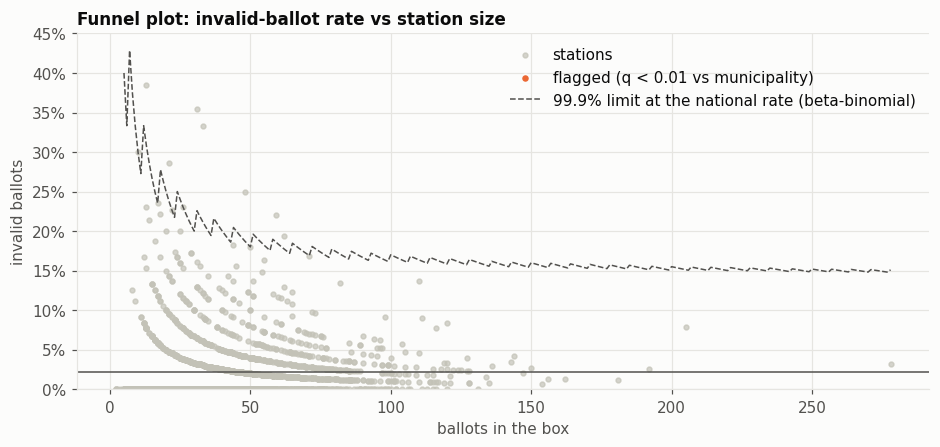

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ok = ~P["flag_invalid"]
ax.scatter(P.loc[ok, "box"], P.loc[ok, "invalid rate"], s=10, color=MUTED, alpha=0.7, label="stations", zorder=2)
ax.scatter(P.loc[~ok, "box"], P.loc[~ok, "invalid rate"], s=30, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="flagged (q < 0.01 vs municipality)")
nn = np.arange(5, P["box"].max() + 1)
a, b = nat_rate * (1 - rho_inv) / rho_inv, (1 - nat_rate) * (1 - rho_inv) / rho_inv
ax.plot(nn, stats.betabinom.ppf(0.999, nn, a, b) / nn, color=INK2, lw=1, ls="--", label="99.9% limit at the national rate (beta-binomial)")
ax.axhline(nat_rate, color=INK2, lw=1)
ax.set_xlabel("ballots in the box"); ax.set_ylabel("invalid ballots"); ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.45); ax.legend(loc="upper right")
ax.set_title("Funnel plot: invalid-ballot rate vs station size")
plt.show()

**Why so few (or no) flags?** Invalid-ballot rates vary much more between committees than chance alone allows (ρ above; more than half
of paper stations report zero invalid ballots, while others report 10–15%). That spread most likely reflects how strictly each
committee judges a doubtful ballot. Once this committee-to-committee variation is taken into account, no individual station stands out.
A plain binomial test would have flagged dozens of stations, but only because it ignores that spread.

In [9]:
P["top candidate"] = P[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
P.loc[P["flag_invalid"], ["place", "address", "box", "invalid", "invalid rate", "municipality rate", "top candidate", "q"]] \
    .sort_values("q").style.format({"invalid rate": "{:.1%}", "municipality rate": "{:.1%}", "q": "{:.1e}"})

,place,address,box,invalid,invalid rate,municipality rate,top candidate,q
section,,,,,,,,


In [10]:
rows = {}
for c in OUTCOMES:
    X = demean(P[["invalid rate"]], P["municipality"], P["box"])
    y = demean(P[f"share|{c}"], P["municipality"], P["box"])[:, 0]
    b, se = wls_cluster(y, X, P["box"], P["municipality"])
    rows[short(c)] = {"slope": b[0], "95% CI": f"{b[0] - 1.96*se[0]:+.2f} … {b[0] + 1.96*se[0]:+.2f}",
                      "share change if invalid rate +5 pts": b[0] * 0.05}
inv_slopes = pd.DataFrame(rows).T
inv_slopes.style.format({"slope": "{:+.2f}", "share change if invalid rate +5 pts": "{:+.1%}"})

,slope,95% CI,share change if invalid rate +5 pts
Илияна Йотова,+0.01,-0.15 … +0.18,+0.1%
Андрей Гюров,-0.36,-0.55 … -0.18,-1.8%
Костадин Костадинов,-0.16,-0.25 … -0.08,-0.8%
Радостин Василев,+0.06,-0.02 … +0.14,+0.3%
Не подкрепям никого,+0.09,+0.00 … +0.18,+0.4%


**How to read the slopes.** If invalid ballots were a random slice of all ballots, every slope would be ~0. If they were taken
entirely from candidate X, X's slope would be close to −(1 − X's share), roughly −0.7.

A negative slope for a candidate whose voters are younger or more educated can also be innocent. Older, less experienced voters
spoil more ballots and vote differently, even within one municipality. The RDD in section 1 helps: if paper counts were
systematically hurting a candidate, that candidate would gain at the switch to machines, and no such jump appears.

**Scale check:** there are only ~2,300 invalid ballots in all paper stations combined. Even if every one had been stolen from a
single candidate, it wouldn't change the ranking.

## 3. Voters added on election day (“под чертата”)
Voters not on the printed list can be added on the day (e.g. voting at a temporary address). Adding fictitious voters is a known
channel for fraud. Two checks:

**(a) How do added voters vote?** Each station's result mixes regular voters and added voters. Regressing a candidate's share on
the station's fraction of added voters (comparing stations in the same municipality) estimates **the share among added voters**.

**Watch out for a trap:** the added fraction (added ÷ voted) is mechanically larger where turnout is low. Any candidate who is strong in
low-turnout stations will therefore *look* popular among added voters. So we show the estimate **with and without controlling for
turnout**.

In [11]:
A = dom[(dom["registered"] >= 100) & (dom["voters_added"] / dom["registered"] <= 0.5)].copy()
A["added fraction"] = A["voters_added"] / A["voted"].clip(lower=1)
A = A[A["added fraction"] <= 1]
turnout_deciles = pd.get_dummies(pd.qcut(A["turnout"], 10), drop_first=True).astype(float)

def added_voter_share(data, cand, group, control_turnout):
    Xraw = data[["added fraction"]]
    if control_turnout:
        Xraw = pd.concat([Xraw, turnout_deciles.loc[data.index]], axis=1)
    keep = (data.groupby(group)["added fraction"].transform("size") >= 2).to_numpy()
    X = demean(Xraw, data[group], data["valid"])[keep]
    y = demean(data[f"share|{cand}"], data[group], data["valid"])[keep, 0]
    b, se = wls_cluster(y, X, data["valid"][keep], data[group][keep])
    base = data[cand].sum() / data["valid"].sum()
    return base, base + b[0], 1.96 * se[0]

specs = {"naive (same municipality)": ("municipality", False),
         "+ control for turnout": ("municipality", True),
         "+ turnout, same building": ("address", True)}
est = {}
for c in OUTCOMES:
    for name, (g, ctl) in specs.items():
        base, val, ci = added_voter_share(A, c, g, ctl)
        est[(short(c), name)] = (base, val, ci)
tab = pd.DataFrame({k: {"regular voters (overall)": v[0], "added voters (est.)": v[1], "± 95% CI": v[2]} for k, v in est.items()}).T
print(f"{len(A):,} stations, {A['voters_added'].sum():,} added voters ({A['voters_added'].sum() / A['voted'].sum():.1%} of all who voted)")
tab.style.format("{:.1%}")

10,624 stations, 58,788 added voters (4.2% of all who voted)


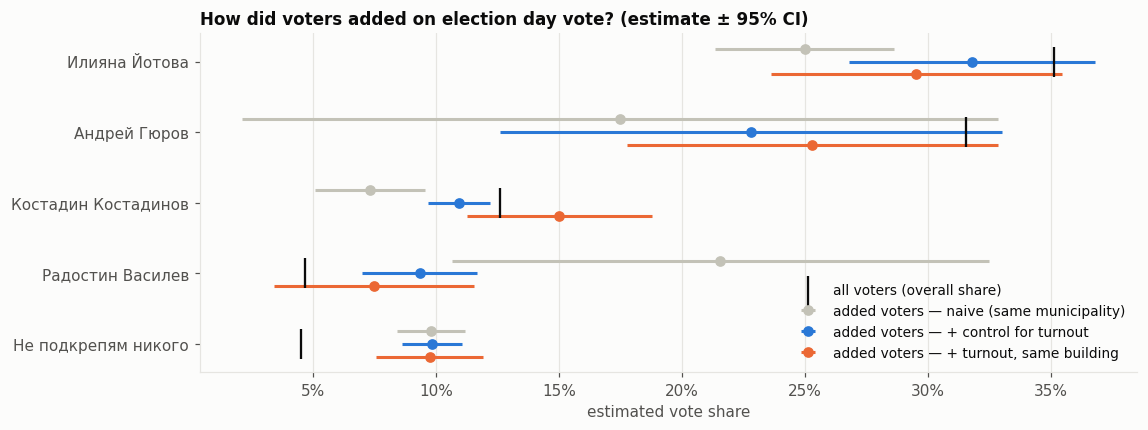

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
cands = [short(c) for c in OUTCOMES]
y0 = np.arange(len(cands))
offsets = {"naive (same municipality)": -0.18, "+ control for turnout": 0.0, "+ turnout, same building": 0.18}
colors = {"naive (same municipality)": MUTED, "+ control for turnout": BLUE, "+ turnout, same building": ORANGE}
for name, off in offsets.items():
    vals = [est[(c, name)] for c in cands]
    ax.errorbar([v[1] for v in vals], y0 + off, xerr=[v[2] for v in vals], fmt="o", ms=6, color=colors[name],
                ecolor=colors[name], elinewidth=2, capsize=0, label=f"added voters — {name}")
ax.scatter([est[(c, 'naive (same municipality)')][0] for c in cands], y0, marker="|", s=400, color=INK, zorder=4, label="all voters (overall share)")
ax.set_yticks(y0, cands); ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.set_xlabel("estimated vote share"); ax.legend(loc="lower right", fontsize=9)
ax.set_title("How did voters added on election day vote? (estimate ± 95% CI)")
plt.show()

**(b) Stations with unusually many added voters** relative to the rest of their municipality (added ÷ registered, beta-binomial,
q < 0.01). Hospitals and prisons were already excluded, but some flagged stations will have innocent reasons: student dorms, resorts,
workplaces.

In [13]:
A["added rate"] = A["voters_added"] / A["registered"]
nat_added = A["voters_added"].sum() / A["registered"].sum()
A["municipality added rate"] = loo_rate(A["voters_added"], A["registered"], A["municipality"], nat_added)
A["q_added"], rho_add = betabinom_outliers(A["voters_added"], A["registered"], A["municipality added rate"].clip(lower=0.002))
A["flag_added"] = A["q_added"] < 0.01
A["top candidate"] = A[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
A["top share"] = A[[f"share|{c}" for c in cand_cols]].max(axis=1)
print(f"over-dispersion ρ = {rho_add:.3f};  flagged stations: {A['flag_added'].sum()}")
A.loc[A["flag_added"], ["place", "address", "registered", "voters_added", "voted", "added rate", "municipality added rate",
                         "top candidate", "top share", "q_added"]].sort_values("q_added").head(40).style.format(
    {"added rate": "{:.1%}", "municipality added rate": "{:.1%}", "top share": "{:.0%}", "q_added": "{:.1e}"})

over-dispersion ρ = 0.004;  flagged stations: 60


,place,address,registered,voters_added,voted,added rate,municipality added rate,top candidate,top share,q_added
section,,,,,,,,,,
234609083,гр.София,бул. „Никола Вапцаров“ № 51-Б,673,138,154,20.5%,1.7%,Андрей Гюров,54%,0.0e+00
234616002,гр.София,"ГР.СОФИЯ, ж.к. Студентски град ,бл.26,ет.ІІ",750,259,498,34.5%,1.7%,Андрей Гюров,63%,0.0e+00
192700215,гр.Русе,"УМБАЛ „МЕДИКА“- АД; гр. Русе, ул. „Рига“№35",166,81,131,48.8%,1.0%,Илияна Йотова,40%,0.0e+00
020400338,гр.Бургас,"ГР.БУРГАС, УМБАЛ Дева Мария -кв.Ветрен, ул. Александър Стамболийски №32",109,53,56,48.6%,1.0%,Андрей Гюров,39%,0.0e+00
234610115,гр.София,"ВОЕННОМЕДИЦИНСКА АКАДЕМИЯ, бул. „Св. Георги Софийски” № 3, учебна зала № 2, първи етаж /ет. I/ в основната сграда на ВМА",851,152,192,17.9%,1.7%,Андрей Гюров,44%,0.0e+00
254611082,гр.София,"ГР.СОФИЯ, МБАЛ НАДЕЖДА , ул. Блага вест №3",221,82,85,37.1%,0.9%,Андрей Гюров,36%,0.0e+00
234616006,гр.София,"ГР.СОФИЯ, ж.к. Студентски град ,бл.54,вх.Б,ет.ІІ",947,230,528,24.3%,1.7%,Андрей Гюров,68%,0.0e+00
234616003,гр.София,"ГР.СОФИЯ, ж.к. Студентски град ,бл.38,ет.ІІ",750,161,450,21.5%,1.7%,Андрей Гюров,70%,0.0e+00
234610111,гр.София,"СБАЛАГ „МАЙЧИН Дом” ЕАД, ул. „Здраве” № 2, кабинет 121, първи етаж /ет. I/- основна сграда",166,51,57,30.7%,1.7%,Андрей Гюров,49%,1.8e-11


In [14]:
flagged = A[A["flag_added"]]
comp = pd.DataFrame({
    "flagged stations": flagged[OUTCOMES].sum() / flagged["valid"].sum(),
    "all stations": A[OUTCOMES].sum() / A["valid"].sum(),
})
comp.index = [short(c) for c in comp.index]
print(f"Vote shares in the {len(flagged)} stations with unusually many added voters vs everywhere:")
comp.style.format("{:.1%}")

Vote shares in the 60 stations with unusually many added voters vs everywhere:


,flagged stations,all stations
Илияна Йотова,22.8%,35.1%
Андрей Гюров,48.6%,31.5%
Костадин Костадинов,9.0%,12.6%
Радостин Василев,4.0%,4.7%
Не подкрепям никого,5.9%,4.5%


## 4. Do the protocols add up?
The CIK data-entry software rejects many inconsistent protocols, so most identities hold by construction. What slips through is
still informative:

In [15]:
pp = main.reindex(dom.index)
f = dom["form"]
paper_f, mach_f = f.isin([24, 28]), f.isin([25, 29])
sig, box, inv_, valid7, cand71, none72 = (num(pp[i]) for i in (11, 12, 13, 15, 16, 17))
received, destroyed, unused = num(pp[6]), num(pp[7]), num(pp[8])
mach_votes = num(pp[14])
cand_sum = dom[cand_cols].sum(axis=1)

checks = {
    "paper: signatures ≠ ballots in the box": paper_f & (sig != box),
    "paper: ballots in box ≠ invalid + valid": paper_f & (box != inv_ + valid7),
    "paper: valid ≠ candidates + 'none'": paper_f & (valid7 != cand71 + none72),
    "paper: received ≠ destroyed + unused + in box": paper_f & (received != destroyed + unused + box),
    "machine: signatures ≠ machine votes": mach_f & (sig != mach_votes),
    "votes per candidate ≠ protocol item 7.1": paper_f & (cand_sum != cand71),
    "more voters than registered": dom["voted"] > dom["registered"],
}
check_df = pd.DataFrame(checks)
dom["arith_issues"] = check_df.apply(lambda r: "; ".join(k for k, v in r.items() if v), axis=1)
dom["flag_arith"] = check_df.any(axis=1)
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="stations").to_frame()

,stations
paper: signatures ≠ ballots in the box,0
paper: ballots in box ≠ invalid + valid,0
paper: valid ≠ candidates + 'none',1
paper: received ≠ destroyed + unused + in box,0
machine: signatures ≠ machine votes,31
votes per candidate ≠ protocol item 7.1,1
more voters than registered,0


In [16]:
detail = dom.loc[dom["flag_arith"], ["place", "form", "registered", "voted"]].copy()
detail["signatures"] = sig[dom["flag_arith"]]
detail["ballots in box / machine votes"] = np.where(paper_f[dom["flag_arith"]], box[dom["flag_arith"]], mach_votes[dom["flag_arith"]])
detail["difference"] = detail["signatures"] - detail["ballots in box / machine votes"]
detail["issues"] = dom.loc[dom["flag_arith"], "arith_issues"]
detail.sort_values("difference", key=abs, ascending=False)

,place,form,registered,voted,signatures,ballots in box / machine votes,difference,issues
section,,,,,,,,
170100100,с.Мулдава,25,623,41,41,37.0,4.0,machine: signatures ≠ machine votes
265900003,гр.Долна баня,25,602,164,164,161.0,3.0,machine: signatures ≠ machine votes
234610065,гр.София,25,515,191,191,188.0,3.0,machine: signatures ≠ machine votes
221100007,гр.Златоград,25,753,164,164,162.0,2.0,machine: signatures ≠ machine votes
282200020,с.Голямо църквище,25,347,56,56,54.0,2.0,machine: signatures ≠ machine votes
264500005,гр.Сливница,25,558,154,154,152.0,2.0,machine: signatures ≠ machine votes
234609014,гр.София,25,702,292,292,290.0,2.0,machine: signatures ≠ machine votes
172600015,с.Брестник,25,653,186,186,184.0,2.0,machine: signatures ≠ machine votes
303000054,гр.Шумен,25,877,202,202,204.0,-2.0,machine: signatures ≠ machine votes


**Reading it:** a difference of 1–2 between signatures and ballots happens honestly (a voter signs and leaves, or forgets to sign).
Large gaps (dozens of ballots) mean either a serious recording error or ballots that can't be accounted for. They are the first
protocols to look up.

## 5. Combined watch-list
One flag alone is usually innocent. **Several independent flags in the same station** are much more interesting. We combine the
flags from this notebook with those from the turnout notebook:

| flag | meaning |
|---|---|
| `invalid` | far more invalid ballots than the municipality (q < 0.01) |
| `added` | far more voters added on the day than the municipality (q < 0.01) |
| `arith` | protocol doesn't add up |
| `list_error` | ~100% turnout with a voter list much smaller than the same-building neighbours |
| `extreme` | turnout > 70% and one candidate > 70% |
| `low_t_bloc` | turnout < 40% of the municipality median and one candidate > 50% |

In [17]:
w = dom.copy()
w["flag_invalid"] = P["flag_invalid"].reindex(w.index, fill_value=False)
w["flag_added"] = A["flag_added"].reindex(w.index, fill_value=False)

bld_list = w.groupby("address")["voters_list"].transform(lambda s: s.sum() - s) / (w.groupby("address")["voters_list"].transform("size") - 1)
w["flag_list_error"] = (w["turnout"] >= 0.95) & (w["voters_list"] < 0.6 * bld_list)

shares = w[[f"share|{c}" for c in cand_cols]]
w["top candidate"] = shares.idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
w["top share"] = shares.max(axis=1)
regular = (w["registered"] >= 100) & (w["voters_added"] / w["registered"] <= 0.5)
w["flag_extreme"] = regular & (w["turnout"] > 0.7) & (w["top share"] > 0.7)
muni_t = w[regular].groupby("municipality")["turnout"].median()
w["flag_low_t_bloc"] = regular & (w["turnout"] < 0.4 * w["municipality"].map(muni_t)) & (w["top share"] > 0.5)

FLAGS = ["flag_invalid", "flag_added", "flag_arith", "flag_list_error", "flag_extreme", "flag_low_t_bloc"]
w["n_flags"] = w[FLAGS].sum(axis=1)
w["flags"] = w[FLAGS].apply(lambda r: ", ".join(k.replace("flag_", "") for k, v in r.items() if v), axis=1)

summary = pd.Series({k.replace("flag_", ""): int(w[k].sum()) for k in FLAGS} | {"≥ 2 flags": int((w["n_flags"] >= 2).sum())}, name="stations")
summary.to_frame()

,stations
invalid,0
added,60
arith,32
list_error,46
extreme,2
low_t_bloc,101
≥ 2 flags,1


In [18]:
watch = w[w["n_flags"] >= 1].sort_values(["n_flags", "top share"], ascending=False)
cols = ["n_flags", "flags", "place", "address", "registered", "voters_added", "voted", "turnout", "invalid", "top candidate", "top share"]
watch[cols].to_csv("watchlist.csv")
print(f"{len(watch)} flagged stations saved to watchlist.csv")
watch.loc[watch["n_flags"] >= 2, cols].style.format({"turnout": "{:.0%}", "top share": "{:.0%}"})

240 flagged stations saved to watchlist.csv


,n_flags,flags,place,address,registered,voters_added,voted,turnout,invalid,top candidate,top share
section,,,,,,,,,,,
030602134,2,"added, list_error",гр.Варна,"ГР.ВАРНА, Икономически университет, бул. Княз Борис I №77",296,27,296,100%,0,Андрей Гюров,41%


In [19]:
# Which candidate leads in flagged stations, compared with how often each candidate leads overall?
lead_all = w.loc[regular, "top candidate"].value_counts(normalize=True)
lead_flag = pd.DataFrame({k.replace("flag_", ""): w.loc[w[k], "top candidate"].value_counts() for k in FLAGS}).fillna(0).astype(int)
lead_flag["share of all stations they lead"] = lead_all.reindex(lead_flag.index)
lead_flag.sort_values("share of all stations they lead", ascending=False).head(8).style.format({"share of all stations they lead": "{:.0%}"})

,invalid,added,arith,list_error,extreme,low_t_bloc,share of all stations they lead
top candidate,,,,,,,
Илияна Йотова,0,23,24,29,2,46,69%
Андрей Гюров,0,37,7,17,0,5,27%
Радостин Василев,0,0,0,0,0,50,3%
Костадин Костадинов,0,0,1,0,0,0,0%


## 6. Conclusions

| Check | Finding | Fraud signal? |
|---|---|---|
| **Paper vs machine (RDD at 300 voters)** | No jump for any candidate or for turnout: within ±2–3 pts (municipality FE, ±100 voters). The positive control (invalid ballots) shows the expected −2 pt drop, so the method can see effects of this size. | **No** systematic paper-count manipulation |
| **Bunching at 300** | *Fewer* stations just below 300 than just above (96 vs 134). That's the opposite of what “avoiding machines” would produce. | **No** |
| **Invalid-ballot outliers** | 2.2% of paper ballots are invalid. Rates vary enormously between committees (53% report zero), but no station is extreme given that variation. | **No** |
| **Who loses when invalid ballots are high** | Гюров's share is a bit lower where invalid rates are higher (−1.8 pts per +5 pts of invalid ballots). That is consistent with demography, and the RDD shows no paper penalty for him. At most ~2,300 ballots are involved. | **No meaningful signal** |
| **How added voters vote** | The naive estimate says added voters strongly favour Василев (22%), but that is a **turnout artefact**: with turnout controlled it drops to 7–9%. The robust finding: added voters pick “Не подкрепям никого” twice as often (≈10% vs 4.5%). | **No** (instructive trap) |
| **Stations with many added voters** | 60 stations, almost all student dorms and universities, hospitals, care homes, sanatoria, prisons and the Military Medical Academy. These are places where people naturally vote away from home; they lean Гюров (students). | **No** |
| **Protocol arithmetic** | Paper protocols are fully consistent. 31 machine stations differ by 1–4 between signatures and machine votes. These are trivial recording slips. | **No** |
| **Combined watch-list** | 240 stations carry one flag; **only 1 carries two**: a student section at the Varna University of Economics (list error + many added voters, innocent). The independent red flags don't pile up anywhere. | **No multi-flag hotspots** |

### Bottom line
**The counting stage looks clean.** Paper ballots, which committees could manipulate, give the same results as machines, which
they can't. Invalid ballots and voters added on the day behave the way honest processes do. The protocols add up.

The **one pattern that keeps reappearing across notebooks** is the low-turnout bloc pattern for **Василев**. He leads 50 of the 101
stations where turnout is far below the municipal norm and one candidate takes more than half the vote, while leading only ~3% of
stations overall. This is consistent with organised/controlled voting in a few dozen neighbourhoods. It involves on the order of 1,000–2,000
votes and doesn't affect the outcome.

### Across all three notebooks
| Notebook | Looks for | Result |
|---|---|---|
| `benford.ipynb` | invented numbers | nothing beyond what honest counts produce |
| `turnout_fingerprint.ipynb` | ballot stuffing, extreme fraud | no stuffing signature; 39 voter-list data-entry errors; a localised low-turnout bloc pattern |
| `ballot_anomalies.ipynb` | counting-stage manipulation, voter-list abuse | clean; no stations with multiple red flags |

`watchlist.csv` lists every flagged station with its reasons, for checking against the scanned protocols on the CIK website.

### Remaining blind spots
Statistics on published protocols can't see **vote buying of people who would have voted anyway**, **pressure on dependent
voters**, or problems that happen identically in paper and machine stations. The machine records in `suemg/` can still be audited
against the protocols directly.